# Marketing Channel Performance: Robinhood, H1 2025

**Question:** which paid channels are worth the money, and how should the H2 budget be split?

**Data**
- `ad_spend.csv`: daily impressions, clicks and spend per paid campaign, Jan to Jun 2025
- `signups.csv`: one row per new user, with the credited channel/campaign, whether they started Robinhood Gold, and their revenue in the first 90 days

**Steps**
1. Load and reconcile the two files (channel keys, duplicate spend rows)
2. Funnel metrics per campaign: spend, impressions, clicks, CTR, CPC
3. Outcome metrics: signups, paying subscribers, cost per signup, cost per paying subscriber, ROAS (90-day)
4. Paid vs organic and referral conversion to paid
5. Month-by-month trends and the campaign that stopped
6. Which metric to judge on, and how it changes the ranking
7. H2 budget recommendation and risks

In [1]:
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
FIG = Path("figures"); FIG.mkdir(exist_ok=True)

# Chart styling: reference palette (light mode), hairline grid, recessive axes
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10, "text.color": INK,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "figure.dpi": 110,
})

## 1. Load and reconcile the files

In [2]:
ad_spend = pd.read_csv("ad_spend.csv", parse_dates=["date"])
signups = pd.read_csv("signups.csv", parse_dates=["signup_date", "subscription_start_date"])
print(ad_spend.shape, signups.shape)
ad_spend.head()

(1046, 6) (18840, 7)


,date,channel,campaign,impressions,clicks,spend
0,2025-01-01,Paid Search,brand_search,1357,73,55.50
1,2025-01-01,Paid Search,generic_search,4767,112,186.15
2,2025-01-01,Paid Social,prospecting_video,37197,447,222.72
3,2025-01-01,Paid Social,retargeting,5456,85,70.38
4,2025-01-01,Display,display_network,63070,68,148.40


In [3]:
# The two files spell channels differently ("Paid Social" vs "paid_social"), so build a shared key
ad_spend["channel_key"] = ad_spend["channel"].str.lower().str.replace(" ", "_")
signups["channel_key"] = signups["channel"].str.lower().str.replace(" ", "_")

spend_pairs = set(map(tuple, ad_spend[["channel_key", "campaign"]].drop_duplicates().values))
signup_pairs = set(map(tuple, signups.dropna(subset=["campaign"])[["channel_key", "campaign"]].drop_duplicates().values))
print("Raw channel names in ad_spend:", sorted(ad_spend["channel"].unique()))
print("Raw channel names in signups: ", sorted(signups["channel"].unique()))
print("Paid pairs only in ad_spend:", spend_pairs - signup_pairs)
print("Paid pairs only in signups: ", signup_pairs - spend_pairs)
print("Unpaid channels (no campaign):", sorted(signups.loc[signups["campaign"].isna(), "channel_key"].unique()))

Raw channel names in ad_spend: ['Affiliate', 'Display', 'Paid Search', 'Paid Social']
Raw channel names in signups:  ['affiliate', 'display', 'organic', 'paid_search', 'paid_social', 'referral']
Paid pairs only in ad_spend: set()
Paid pairs only in signups:  set()
Unpaid channels (no campaign): ['organic', 'referral']


In [4]:
# Duplicate spend rows: the same campaign-day appearing twice would double-count spend
dupes = ad_spend[ad_spend.duplicated(keep=False)].sort_values(["date", "campaign"])
print(f"Exact duplicate rows: {ad_spend.duplicated().sum()}  "
      f"(duplicate campaign-days: {ad_spend.duplicated(['date', 'channel_key', 'campaign']).sum()})")
print(f"Spend that would be double-counted: ${ad_spend[ad_spend.duplicated()]['spend'].sum():,.2f}")
display(dupes)

ad_spend = ad_spend.drop_duplicates().reset_index(drop=True)
assert not ad_spend.duplicated(["date", "channel_key", "campaign"]).any()
print("Rows after de-duplication:", len(ad_spend))

Exact duplicate rows: 7  (duplicate campaign-days: 7)
Spend that would be double-counted: $920.24


,date,channel,campaign,impressions,clicks,spend,channel_key
311,2025-04-14,Display,display_network,55292,63,143.88,display
628,2025-04-14,Display,display_network,55292,63,143.88,display
321,2025-05-10,Paid Social,prospecting_video,23788,258,140.36,paid_social
782,2025-05-10,Paid Social,prospecting_video,23788,258,140.36,paid_social
151,2025-05-21,Affiliate,finance_blogs,4308,42,96.66,affiliate
844,2025-05-21,Affiliate,finance_blogs,4308,42,96.66,affiliate
557,2025-05-21,Paid Social,prospecting_video,34288,431,213.54,paid_social
842,2025-05-21,Paid Social,prospecting_video,34288,431,213.54,paid_social
228,2025-05-28,Paid Search,generic_search,4732,117,184.79,paid_search
876,2025-05-28,Paid Search,generic_search,4732,117,184.79,paid_search


Rows after de-duplication: 1039


In [5]:
# Other sanity checks
checks = {
    "nulls in ad_spend": int(ad_spend.isna().sum().sum()),
    "negative spend/clicks/impressions": int((ad_spend[["spend", "clicks", "impressions"]] < 0).sum().sum()),
    "clicks > impressions": int((ad_spend["clicks"] > ad_spend["impressions"]).sum()),
    "duplicate user_id": int(signups["user_id"].duplicated().sum()),
    "plan without start date (or vice versa)": int((signups["plan"].isna() != signups["subscription_start_date"].isna()).sum()),
    "subscription before signup": int((signups["subscription_start_date"] < signups["signup_date"]).sum()),
    "revenue from non-payers": int(((signups["revenue_first_90_days"] > 0) & signups["plan"].isna()).sum()),
}
display(pd.Series(checks, name="count").to_frame())

coverage = ad_spend.groupby(["channel_key", "campaign"]).agg(
    first_day=("date", "min"), last_day=("date", "max"), days=("date", "nunique"))
display(coverage)
print("Revenue by plan:")
display(signups.groupby(signups["plan"].fillna("none"))["revenue_first_90_days"].describe()[["count", "mean", "min", "max"]])

,count
nulls in ad_spend,0
negative spend/clicks/impressions,0
clicks > impressions,0
duplicate user_id,0
plan without start date (or vice versa),0
subscription before signup,0
revenue from non-payers,0


first_day   last_day  days
channel_key campaign                                     
affiliate   finance_blogs     2025-01-01 2025-06-30   181
display     display_network   2025-01-01 2025-05-14   134
paid_search brand_search      2025-01-01 2025-06-30   181
            generic_search    2025-01-01 2025-06-30   181
paid_social prospecting_video 2025-01-01 2025-06-30   181
            retargeting       2025-01-01 2025-06-30   181

Revenue by plan:


,count,mean,min,max
plan,,,,
annual,653.0,79.990000,79.99,79.99
monthly,1602.0,25.692135,9.99,29.97
none,16585.0,0.000000,0.00,0.00


**Findings:** the channel names needed a shared key, and 7 spend rows were exact duplicates ($920 of spend, removed). Everything else is clean. Every paid campaign in `ad_spend` has matching signups and vice versa. `organic` and `referral` exist only in `signups` because they have no spend. All campaigns run every day of the half except **display_network, which stops after 14 May**.

Paying users are on a monthly plan (up to $29.97 over 90 days) or an annual plan ($79.99 paid upfront). Non-payers bring in $0, so a signup has no value until it converts to Gold.

## 2. Funnel metrics per campaign

In [6]:
spend_by_campaign = ad_spend.groupby(["channel_key", "campaign"]).agg(
    spend=("spend", "sum"), impressions=("impressions", "sum"), clicks=("clicks", "sum"))
spend_by_campaign["ctr"] = spend_by_campaign["clicks"] / spend_by_campaign["impressions"]
spend_by_campaign["cpc"] = spend_by_campaign["spend"] / spend_by_campaign["clicks"]
spend_by_campaign.sort_values("spend", ascending=False).style.format(
    {"spend": "${:,.0f}", "impressions": "{:,.0f}", "clicks": "{:,.0f}", "ctr": "{:.2%}", "cpc": "${:.2f}"})

,,spend,impressions,clicks,ctr,cpc
channel_key,campaign,,,,,
paid_search,generic_search,"$35,939","898,188","22,153",2.47%,$1.62
paid_social,prospecting_video,"$33,916","5,662,300","68,085",1.20%,$0.50
display,display_network,"$16,455","6,605,031","7,844",0.12%,$2.10
affiliate,finance_blogs,"$15,392","706,611","7,752",1.10%,$1.99
paid_social,retargeting,"$12,987","1,084,880","17,245",1.59%,$0.75
paid_search,brand_search,"$10,197","267,763","12,089",4.51%,$0.84


Brand search has the best click-through rate (4.5%) because people searching for "Robinhood" already want it. Prospecting video buys the cheapest clicks ($0.50) and the most of them. Display serves 6.6M impressions at a 0.12% CTR and is the most expensive per click.

## 3. Spend to outcomes

In [7]:
signups["is_paying"] = signups["plan"].notna()
outcomes = signups.groupby(["channel_key", signups["campaign"].fillna("(none)")]).agg(
    signups=("user_id", "size"),
    paying_subs=("is_paying", "sum"),
    annual_subs=("plan", lambda p: (p == "annual").sum()),
    revenue_90d=("revenue_first_90_days", "sum"),
)
outcomes.index.names = ["channel_key", "campaign"]

metrics = outcomes.join(spend_by_campaign, how="left")
metrics["paid_channel"] = metrics["spend"].notna()
metrics["signup_to_paid"] = metrics["paying_subs"] / metrics["signups"]
metrics["click_to_signup"] = metrics["signups"] / metrics["clicks"]
metrics["cost_per_signup"] = metrics["spend"] / metrics["signups"]
metrics["cost_per_paying_sub"] = metrics["spend"] / metrics["paying_subs"]
metrics["roas_90d"] = metrics["revenue_90d"] / metrics["spend"]
metrics["revenue_per_paying_sub"] = metrics["revenue_90d"] / metrics["paying_subs"]
metrics["annual_share"] = metrics["annual_subs"] / metrics["paying_subs"]

campaign_cols = ["spend", "impressions", "clicks", "ctr", "cpc", "signups", "click_to_signup", "paying_subs",
                 "signup_to_paid", "cost_per_signup", "cost_per_paying_sub", "revenue_90d", "roas_90d",
                 "revenue_per_paying_sub", "annual_share"]
campaign_metrics = metrics[campaign_cols].sort_values("cost_per_paying_sub")
campaign_metrics.round(4).to_csv(OUT / "campaign_metrics.csv")

fmt = {"spend": "${:,.0f}", "impressions": "{:,.0f}", "clicks": "{:,.0f}", "ctr": "{:.2%}", "cpc": "${:.2f}",
       "signups": "{:,.0f}", "click_to_signup": "{:.1%}", "paying_subs": "{:,.0f}", "signup_to_paid": "{:.1%}",
       "cost_per_signup": "${:,.2f}", "cost_per_paying_sub": "${:,.2f}", "revenue_90d": "${:,.0f}",
       "roas_90d": "{:.2f}x", "revenue_per_paying_sub": "${:.2f}", "annual_share": "{:.0%}"}
campaign_metrics.style.format(fmt, na_rep="-")

,,spend,impressions,clicks,ctr,cpc,signups,click_to_signup,paying_subs,signup_to_paid,cost_per_signup,cost_per_paying_sub,revenue_90d,roas_90d,revenue_per_paying_sub,annual_share
channel_key,campaign,,,,,,,,,,,,,,,
paid_search,brand_search,"$10,197","267,763","12,089",4.51%,$0.84,"2,177",18.0%,465,21.4%,$4.68,$21.93,"$19,470",1.91x,$41.87,30%
paid_social,retargeting,"$12,987","1,084,880","17,245",1.59%,$0.75,"2,465",14.3%,418,17.0%,$5.27,$31.07,"$17,411",1.34x,$41.65,30%
paid_search,generic_search,"$35,939","898,188","22,153",2.47%,$1.62,"2,008",9.1%,432,21.5%,$17.90,$83.19,"$16,941",0.47x,$39.21,25%
affiliate,finance_blogs,"$15,392","706,611","7,752",1.10%,$1.99,864,11.1%,162,18.8%,$17.82,$95.02,"$6,316",0.41x,$38.99,24%
paid_social,prospecting_video,"$33,916","5,662,300","68,085",1.20%,$0.50,"6,484",9.5%,213,3.3%,$5.23,$159.23,"$8,765",0.26x,$41.15,28%
display,display_network,"$16,455","6,605,031","7,844",0.12%,$2.10,268,3.4%,8,3.0%,$61.40,"$2,056.83",$540,0.03x,$67.48,75%
organic,(none),-,-,-,-,-,"3,511",-,345,9.8%,-,-,"$14,473",-,$41.95,30%
referral,(none),-,-,-,-,-,"1,063",-,212,19.9%,-,-,"$9,476",-,$44.70,34%


In [8]:
# Channel-level roll-up (paid channels plus organic and referral)
channel_metrics = metrics.groupby("channel_key")[["spend", "impressions", "clicks", "signups", "paying_subs", "revenue_90d"]].sum(min_count=1)
channel_metrics["ctr"] = channel_metrics["clicks"] / channel_metrics["impressions"]
channel_metrics["cpc"] = channel_metrics["spend"] / channel_metrics["clicks"]
channel_metrics["signup_to_paid"] = channel_metrics["paying_subs"] / channel_metrics["signups"]
channel_metrics["cost_per_signup"] = channel_metrics["spend"] / channel_metrics["signups"]
channel_metrics["cost_per_paying_sub"] = channel_metrics["spend"] / channel_metrics["paying_subs"]
channel_metrics["roas_90d"] = channel_metrics["revenue_90d"] / channel_metrics["spend"]
channel_metrics = channel_metrics.sort_values("cost_per_paying_sub", na_position="last")
channel_metrics.round(4).to_csv(OUT / "channel_metrics.csv")

paid = metrics[metrics["paid_channel"]]
total_spend, paid_subs, paid_rev = paid["spend"].sum(), paid["paying_subs"].sum(), paid["revenue_90d"].sum()
print(f"Total paid spend: ${total_spend:,.0f} | paying subs from paid: {paid_subs:,} | "
      f"blended cost per paying sub ${total_spend / paid_subs:,.2f} | blended 90-day ROAS {paid_rev / total_spend:.2f}x")
channel_metrics.style.format(fmt, na_rep="-")

Total paid spend: $124,886 | paying subs from paid: 1,698 | blended cost per paying sub $73.55 | blended 90-day ROAS 0.56x


,spend,impressions,clicks,signups,paying_subs,revenue_90d,ctr,cpc,signup_to_paid,cost_per_signup,cost_per_paying_sub,roas_90d
channel_key,,,,,,,,,,,,
paid_search,"$46,136","1,165,951","34,242","4,185",897,"$36,411",2.94%,$1.35,21.4%,$11.02,$51.43,0.79x
paid_social,"$46,903","6,747,180","85,330","8,949",631,"$26,177",1.26%,$0.55,7.1%,$5.24,$74.33,0.56x
affiliate,"$15,392","706,611","7,752",864,162,"$6,316",1.10%,$1.99,18.8%,$17.82,$95.02,0.41x
display,"$16,455","6,605,031","7,844",268,8,$540,0.12%,$2.10,3.0%,$61.40,"$2,056.83",0.03x
organic,-,-,-,"3,511",345,"$14,473",-,-,9.8%,-,-,-
referral,-,-,-,"1,063",212,"$9,476",-,-,19.9%,-,-,-


### The cheapest per signup is not the cheapest per paying subscriber

- **At channel level** the ranking flips. **Paid Social** is the cheapest way to buy a signup ($5.24, against $11.02 for Paid Search). It is **44% more expensive per paying subscriber** ($74 against $51), because only 7% of its signups start Gold.
- **At campaign level**, **prospecting_video** is the 2nd cheapest per signup ($5.23, almost tied with brand search). It ranks **5th of 6 per paying subscriber ($159)**, because only 3.3% of its signups convert. It brings 34% of all signups but only 9% of paying subscribers.
- **retargeting** costs almost the same per signup as prospecting_video ($5.27). Its signups convert 5x as often (17%), so each paying subscriber costs $31.
- **generic_search** and **finance_blogs** look expensive per signup (about $18, 3.8x brand search). Their signups convert well (21.5% and 18.8%), so per paying subscriber they beat prospecting video by about 40-50%.
- **display_network** is the worst on every metric: $2,057 per paying subscriber and 0.03x ROAS.
- **brand_search** is the best on every outcome metric ($4.68 per signup, $21.93 per paying subscriber, 1.91x ROAS). It also has the biggest incrementality caveat (see section 7).

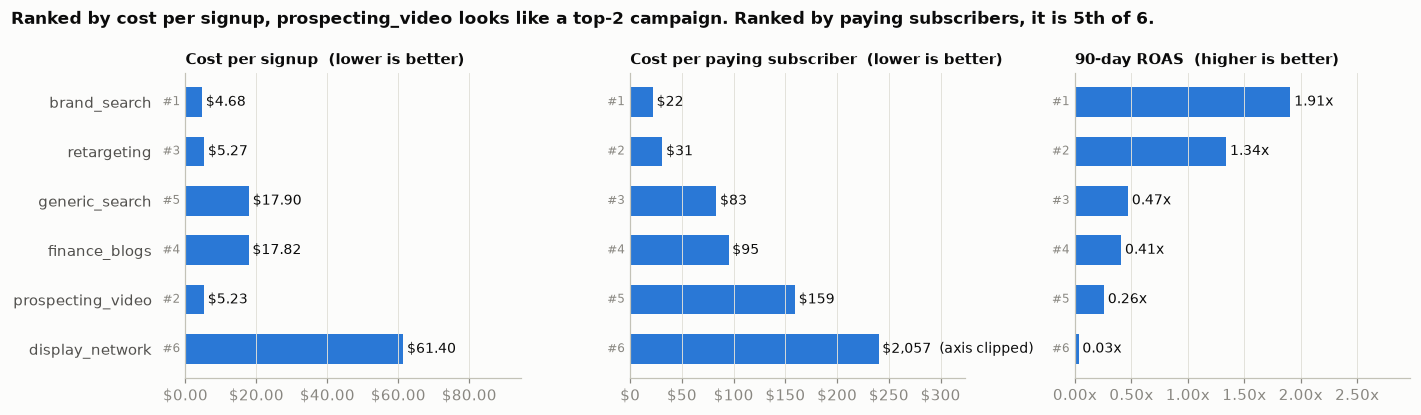

In [9]:
# Figure 1: the same campaigns ranked three ways
order = campaign_metrics.dropna(subset=["spend"]).reset_index()
order["label"] = order["campaign"]
panels = [("cost_per_signup", "Cost per signup", "${:,.2f}", False),
          ("cost_per_paying_sub", "Cost per paying subscriber", "${:,.0f}", False),
          ("roas_90d", "90-day ROAS", "{:.2f}x", True)]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
y = np.arange(len(order))
for ax, (col, title, f, higher_better) in zip(axes, panels):
    vals = order[col].values
    cap = {"cost_per_signup": 70, "cost_per_paying_sub": 240, "roas_90d": 2.2}[col]
    ax.barh(y, np.minimum(vals, cap), height=0.6, color=SERIES[0])
    for yi, v in zip(y, vals):
        clipped = v > cap
        ax.text(min(v, cap) + cap * 0.015, yi, f.format(v) + ("  (axis clipped)" if clipped else ""),
                va="center", fontsize=9, color=INK)
    rank = pd.Series(vals).rank(ascending=not higher_better).astype(int).values
    ax.set_title(title + ("  (higher is better)" if higher_better else "  (lower is better)"), fontsize=10)
    ax.set_xlim(0, cap * 1.35)
    ax.grid(axis="y", visible=False)
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _, f=f: f.format(v)))
    for yi, r in zip(y, rank):
        ax.text(-cap * 0.02, yi, f"#{r}", ha="right", va="center", fontsize=8, color=MUTED)
axes[0].set_yticks(y, order["label"])
axes[0].tick_params(axis="y", pad=22, colors=INK2)
for ax in axes: ax.tick_params(axis="y", length=0)
axes[0].invert_yaxis()
fig.suptitle("Ranked by cost per signup, prospecting_video looks like a top-2 campaign. Ranked by paying subscribers, it is 5th of 6.",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
fig.savefig(FIG / "fig1_campaign_rankings.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Paid campaigns vs organic and referral: signup-to-paid conversion

In [10]:
def wilson_ci(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * math.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

conv = metrics[["signups", "paying_subs", "signup_to_paid", "paid_channel"]].copy().reset_index()
conv["source"] = np.where(conv["paid_channel"], conv["campaign"], conv["channel_key"])
conv[["ci_low", "ci_high"]] = [wilson_ci(k, n) for k, n in zip(conv["paying_subs"], conv["signups"])]
conv = conv.sort_values("signup_to_paid", ascending=False)

summary = pd.DataFrame({
    "group": ["all paid campaigns", "organic", "referral"],
    "signups": [paid["signups"].sum(), *metrics.loc[["organic", "referral"], "signups"].values],
    "paying_subs": [paid_subs, *metrics.loc[["organic", "referral"], "paying_subs"].values],
})
summary["signup_to_paid"] = summary["paying_subs"] / summary["signups"]

def two_prop_z(k1, n1, k2, n2):
    p = (k1 + k2) / (n1 + n2)
    z = (k1 / n1 - k2 / n2) / math.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    return z, math.erfc(abs(z) / math.sqrt(2))

org = metrics.loc[("organic", "(none)")]
for (ch, camp), row in metrics[metrics["paid_channel"]].iterrows():
    z, pval = two_prop_z(row.paying_subs, row.signups, org.paying_subs, org.signups)
    conv.loc[conv["campaign"] == camp, "vs_organic_p"] = pval

display(summary.style.format({"signup_to_paid": "{:.1%}"}))
conv[["source", "signups", "paying_subs", "signup_to_paid", "ci_low", "ci_high", "vs_organic_p"]].style.format(
    {"signup_to_paid": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}", "vs_organic_p": "{:.2g}"}, na_rep="-")

,group,signups,paying_subs,signup_to_paid
0,all paid campaigns,14266,1698,11.9%
1,organic,3511,345,9.8%
2,referral,1063,212,19.9%


,source,signups,paying_subs,signup_to_paid,ci_low,ci_high,vs_organic_p
4,generic_search,2008,432,21.5%,19.8%,23.4%,3.1e-33
3,brand_search,2177,465,21.4%,19.7%,23.1%,1.1e-33
7,referral,1063,212,19.9%,17.7%,22.5%,-
0,finance_blogs,864,162,18.8%,16.3%,21.5%,2.1e-13
6,retargeting,2465,418,17.0%,15.5%,18.5%,4.2e-16
2,organic,3511,345,9.8%,8.9%,10.9%,-
5,prospecting_video,6484,213,3.3%,2.9%,3.7%,4.2e-42
1,display_network,268,8,3.0%,1.5%,5.8%,0.00021


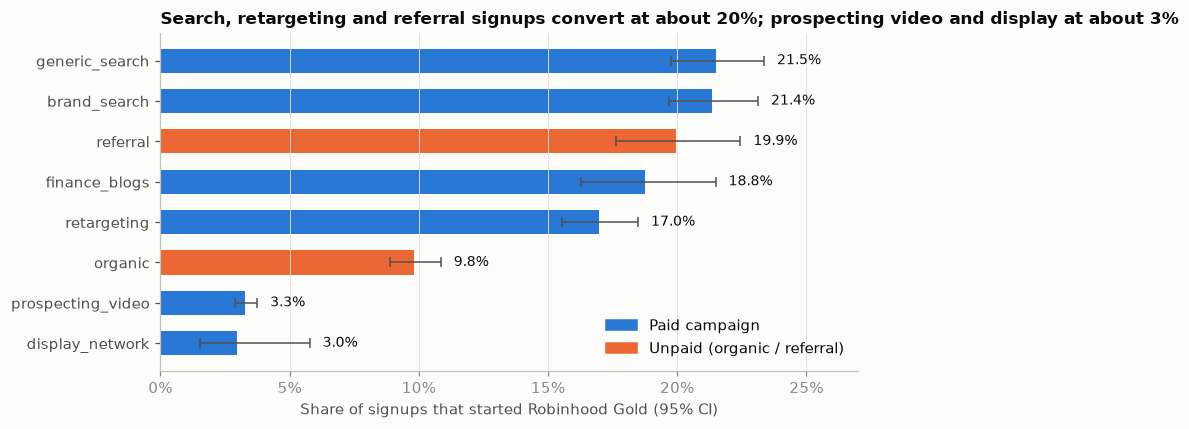

In [11]:
# Figure 2: conversion rate by source, unpaid sources highlighted
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(conv))
colors = [SERIES[0] if p else SERIES[1] for p in conv["paid_channel"]]
ax.barh(y, conv["signup_to_paid"], height=0.6, color=colors)
ax.errorbar(conv["signup_to_paid"], y, xerr=[conv["signup_to_paid"] - conv["ci_low"], conv["ci_high"] - conv["signup_to_paid"]],
            fmt="none", ecolor=INK2, elinewidth=1, capsize=3)
for yi, v, hi in zip(y, conv["signup_to_paid"], conv["ci_high"]):
    ax.text(hi + 0.005, yi, f"{v:.1%}", va="center", fontsize=9, color=INK)
ax.set_yticks(y, conv["source"]); ax.tick_params(axis="y", colors=INK2)
ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_xlim(0, 0.27)
ax.set_xlabel("Share of signups that started Robinhood Gold (95% CI)")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=SERIES[0], label="Paid campaign"), Patch(color=SERIES[1], label="Unpaid (organic / referral)")],
          loc="lower right", frameon=False)
ax.set_title("Search, retargeting and referral signups convert at about 20%; prospecting video and display at about 3%")
fig.tight_layout(); fig.savefig(FIG / "fig2_conversion_by_source.png", dpi=150, bbox_inches="tight"); plt.show()

**Findings**
- Overall, paid signups convert at **11.9%**, only a little above **organic (9.8%)**. The average hides a split.
- **High-intent paid sources** convert at the same rate as **referral (19.9%)** or better: generic search 21.5%, brand search 21.4%, finance blogs 18.8%, retargeting 17.0%. All four are roughly double the organic rate (p < 0.001 for each).
- **Low-intent paid sources** convert at about a third of the organic rate: prospecting video 3.3% and display 3.0%. Their signups mostly stay on free accounts.
- Referral is the best unpaid source, converting at twice the organic rate. Organic brings in more volume (3,511 signups) but converts at half that rate.

## 5. How performance changed over the six months

In [12]:
ad_spend["month"] = ad_spend["date"].dt.to_period("M")
signups["month"] = signups["signup_date"].dt.to_period("M")

m_spend = ad_spend.groupby(["campaign", "month"]).agg(spend=("spend", "sum"), active_days=("date", "nunique"),
                                                      clicks=("clicks", "sum"), impressions=("impressions", "sum"))
m_out = signups.assign(campaign=signups["campaign"].fillna(signups["channel_key"])).groupby(["campaign", "month"]).agg(
    signups=("user_id", "size"), paying_subs=("is_paying", "sum"), revenue_90d=("revenue_first_90_days", "sum"))
monthly = m_out.join(m_spend, how="left")
monthly["signup_to_paid"] = monthly["paying_subs"] / monthly["signups"]
monthly["cost_per_signup"] = monthly["spend"] / monthly["signups"]
monthly["cost_per_paying_sub"] = (monthly["spend"] / monthly["paying_subs"]).replace(np.inf, np.nan)
monthly["roas_90d"] = monthly["revenue_90d"] / monthly["spend"]
monthly.round(4).to_csv(OUT / "monthly_metrics.csv")

def pivot(col):
    return monthly[col].unstack("month")

print("Monthly spend ($)"); display(pivot("spend").round(0))
print("Monthly cost per paying subscriber ($; blank = no paying subs that month)"); display(pivot("cost_per_paying_sub").round(0))
print("Monthly signup-to-paid conversion"); display(pivot("signup_to_paid").style.format("{:.1%}", na_rep="-"))
print("Monthly 90-day ROAS"); display(pivot("roas_90d").round(2))

Monthly spend ($)


month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
campaign,,,,,,
brand_search,1753.0,1581.0,1731.0,1669.0,1769.0,1694.0
display_network,3862.0,3464.0,3859.0,3610.0,1660.0,NaN
finance_blogs,2657.0,2427.0,2550.0,2585.0,2667.0,2507.0
generic_search,6160.0,5609.0,6010.0,6029.0,6147.0,5983.0
organic,NaN,NaN,NaN,NaN,NaN,NaN
prospecting_video,5889.0,5186.0,5795.0,5613.0,5655.0,5777.0
referral,NaN,NaN,NaN,NaN,NaN,NaN
retargeting,2268.0,2012.0,2130.0,2218.0,2244.0,2116.0


Monthly cost per paying subscriber ($; blank = no paying subs that month)


month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
campaign,,,,,,
brand_search,24.0,20.0,23.0,22.0,20.0,23.0
display_network,1287.0,3464.0,NaN,903.0,NaN,NaN
finance_blogs,81.0,106.0,94.0,81.0,111.0,109.0
generic_search,81.0,76.0,81.0,81.0,96.0,85.0
organic,NaN,NaN,NaN,NaN,NaN,NaN
prospecting_video,227.0,153.0,157.0,148.0,145.0,148.0
referral,NaN,NaN,NaN,NaN,NaN,NaN
retargeting,32.0,34.0,30.0,31.0,29.0,31.0


Monthly signup-to-paid conversion


month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
campaign,,,,,,
brand_search,20.7%,23.4%,18.9%,22.5%,22.1%,21.1%
display_network,4.1%,1.6%,0.0%,6.5%,0.0%,-
finance_blogs,20.4%,18.4%,19.1%,22.5%,16.3%,15.6%
generic_search,21.6%,22.2%,20.6%,22.0%,20.6%,22.1%
organic,9.0%,10.1%,9.5%,9.8%,11.3%,9.2%
prospecting_video,2.4%,3.4%,3.3%,3.7%,3.6%,3.4%
referral,20.1%,23.6%,20.4%,16.5%,23.8%,15.6%
retargeting,16.2%,17.1%,17.5%,15.9%,17.1%,18.3%


Monthly 90-day ROAS


month,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06
campaign,,,,,,
brand_search,1.91,1.96,2.02,1.85,1.97,1.74
display_network,0.06,0.02,0.00,0.06,0.00,NaN
finance_blogs,0.50,0.37,0.38,0.49,0.35,0.36
generic_search,0.50,0.51,0.48,0.52,0.36,0.46
organic,NaN,NaN,NaN,NaN,NaN,NaN
prospecting_video,0.16,0.30,0.27,0.27,0.27,0.29
referral,NaN,NaN,NaN,NaN,NaN,NaN
retargeting,1.41,1.31,1.32,1.34,1.44,1.20


In [13]:
last_display_day = ad_spend.loc[ad_spend["campaign"] == "display_network", "date"].max()
last_display_signup = signups.loc[signups["campaign"] == "display_network", "signup_date"].max()
print(f"display_network: last spend day {last_display_day.date()}, last credited signup {last_display_signup.date()}")
print("Other campaigns' last spend day:", ad_spend.groupby("campaign")["date"].max().dt.date.to_dict())

display_network: last spend day 2025-05-14, last credited signup 2025-05-13
Other campaigns' last spend day: {'brand_search': datetime.date(2025, 6, 30), 'display_network': datetime.date(2025, 5, 14), 'finance_blogs': datetime.date(2025, 6, 30), 'generic_search': datetime.date(2025, 6, 30), 'prospecting_video': datetime.date(2025, 6, 30), 'retargeting': datetime.date(2025, 6, 30)}


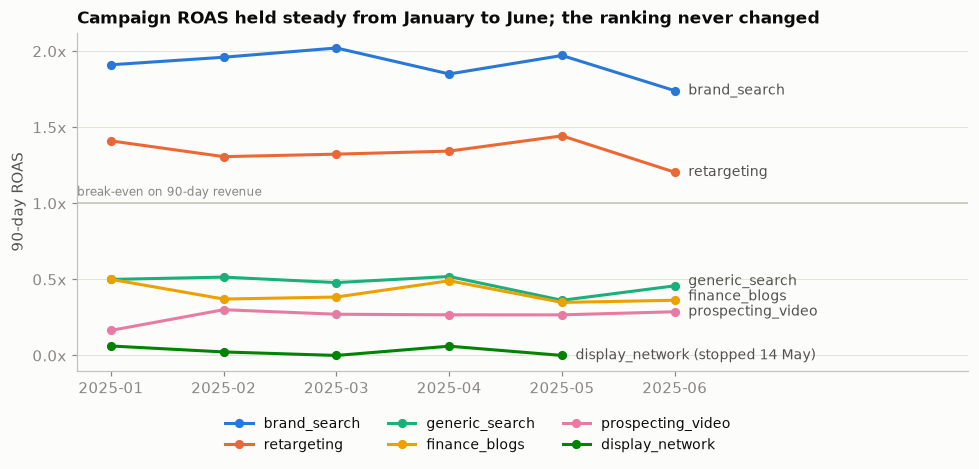

In [14]:
# Figure 3: monthly 90-day ROAS per paid campaign (one axis, direct-labelled endpoints)
paid_campaigns = list(campaign_metrics.dropna(subset=["spend"]).index.get_level_values("campaign"))
color_for = {c: SERIES[i] for i, c in enumerate(paid_campaigns)}  # colour follows the campaign, not its rank
roas_m = pivot("roas_90d").loc[paid_campaigns]
x = np.arange(roas_m.shape[1])

fig, ax = plt.subplots(figsize=(9, 4.4))
for camp, row in roas_m.iterrows():
    vals = row.values.astype(float)
    ax.plot(x, vals, color=color_for[camp], lw=2, marker="o", ms=5, label=camp)
# Endpoint labels, nudged apart so close lines don't collide
ends = []
for camp, row in roas_m.iterrows():
    vals = row.values.astype(float)
    last = np.where(~np.isnan(vals))[0][-1]
    ends.append([camp, last, vals[last]])
ends.sort(key=lambda e: e[2])
for i in range(1, len(ends)):
    if ends[i][1] == ends[i - 1][1] and ends[i][2] - ends[i - 1][2] < 0.1:
        ends[i][2] = ends[i - 1][2] + 0.1
for camp, last, ylab in ends:
    note = " (stopped 14 May)" if camp == "display_network" else ""
    ax.text(last + 0.12, ylab, f"{camp}{note}", va="center", fontsize=9, color=INK2)
ax.axhline(1, color=AXIS, lw=1)
ax.text(-0.3, 1.03, "break-even on 90-day revenue", fontsize=8, color=MUTED, va="bottom")
ax.set_xticks(x, [str(p) for p in roas_m.columns]); ax.set_xlim(-0.3, len(x) + 1.6)
ax.set_ylabel("90-day ROAS"); ax.yaxis.set_major_locator(mtick.MultipleLocator(0.5))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:.1f}x"))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.1), ncol=3, frameon=False, fontsize=9)
ax.set_title("Campaign ROAS held steady from January to June; the ranking never changed")
fig.tight_layout(); fig.savefig(FIG / "fig3_monthly_roas.png", dpi=150, bbox_inches="tight"); plt.show()

**Findings**
- **display_network stopped running after 14 May 2025.** May has 14 days of spend, there is no June spend, and the last credited signup was 13 May. While it ran it spent about $3.6k a month and produced 0 to 4 paying subscribers a month. Two of its five months had zero.
- **The rankings were stable.** Brand search (ROAS 1.7-2.0x) and retargeting (1.2-1.4x) were profitable on 90-day revenue every month. Generic search, finance blogs and prospecting video never broke even on 90-day revenue.
- **Generic search softened in May and June.** Cost per paying subscriber rose from about $76-81 in Jan to Apr to $96 in May and $85 in June. CPC also crept up from $1.60 to $1.68. Worth watching for auction pressure.
- **Prospecting video had a weak January** ($227 per paying subscriber). It then settled at about $145-157, still the worst of the always-on campaigns.
- **Finance blogs are noisy month to month** ($80-111 per paying subscriber), as you would expect from about 25 paying subscribers a month.
- **Daily spend was almost flat for every campaign.** The data shows no test of what happens at higher budgets, so every campaign's response to more spend is unknown.
- Organic signups grew from 536 in January to about 630 in May and June. Referral stayed flat at about 180 a month.

## 6. Which metric should judge channels?

| Metric | What it rewards | Ranking (best to worst) |
|---|---|---|
| Cost per signup | Cheap free accounts | brand_search, **prospecting_video**, retargeting, finance_blogs, generic_search, display |
| Cost per paying subscriber | Gold subscribers, whatever the plan | brand_search, retargeting, generic_search, finance_blogs, **prospecting_video**, display |
| 90-day ROAS | Revenue in the first 90 days | brand_search, retargeting, generic_search, finance_blogs, **prospecting_video**, display |

**Recommended primary metric: cost per paying subscriber (CAC for Gold), read alongside 90-day ROAS.**

- Free accounts earned $0 in this data. A signup only matters if it converts, so cost per signup rewards campaigns that buy cheap, low-intent accounts. Judged on cost per signup, prospecting video would be the place to grow. Judged on paying subscribers, it is the place to cut.
- 90-day ROAS ties spend to revenue. It is biased toward annual plans, because the full $79.99 lands inside the window while a monthly payer shows at most $29.97. It also says nothing about retention after day 90. Cost per paying subscriber treats every Gold user the same, so it is the more stable metric for ranking. ROAS is the check on whether spend is paying back.
- Here cost per paying subscriber and ROAS give the same order, so the switch that changes the ranking is from **signups to paying subscribers**.

## 7. H2 2025 budget recommendation

In [15]:
# Assumes H2 budget is flat with H1 (about $125k). Planned spend per campaign, set from the H1 metrics above.
h1 = campaign_metrics.dropna(subset=["spend"])[["spend", "paying_subs", "cost_per_paying_sub", "roas_90d"]].reset_index(level=0, drop=True)
plan = pd.Series({
    "brand_search":      14_000,   # best CAC; cap by brand query volume (+37%)
    "retargeting":       18_000,   # 2nd best CAC; grow with frequency caps (+39%)
    "generic_search":    38_000,   # best scalable new-demand channel, ~21% conversion (+6%)
    "finance_blogs":     14_000,   # hold roughly flat; move to CPA terms (-9%)
    "prospecting_video": 28_000,   # trim, keep as top-of-funnel feeder for retargeting (-17%)
    "display_network":        0,   # already off; keep off
    "test_reserve":      13_000,   # incrementality tests + new creative/channel tests (~10%)
}, name="h2_budget")

budget = h1.join(plan, how="outer")
budget.loc["test_reserve", "spend"] = 0
budget["change"] = budget["h2_budget"] - budget["spend"]
budget["h2_share"] = budget["h2_budget"] / budget["h2_budget"].sum()
# Naive projection: assumes H1 average cost per paying subscriber holds at the new spend level (an upper bound)
budget["projected_paying_subs"] = budget["h2_budget"] / budget["cost_per_paying_sub"]
budget["projected_revenue_90d"] = budget["h2_budget"] * budget["roas_90d"]
budget = budget.rename(columns={"spend": "h1_spend", "paying_subs": "h1_paying_subs"}).loc[list(plan.index)]
budget.round(2).to_csv(OUT / "budget_plan.csv")

tot = budget[["h1_spend", "h2_budget", "h1_paying_subs", "projected_paying_subs", "projected_revenue_90d"]].sum()
print(f"H1 spend ${tot.h1_spend:,.0f} -> H2 budget ${tot.h2_budget:,.0f}")
print(f"Paying subs from paid media: H1 {tot.h1_paying_subs:,.0f} -> H2 projected {tot.projected_paying_subs:,.0f} "
      f"(excludes test reserve; assumes H1 average CAC holds)")
print(f"90-day revenue: H1 ${paid_rev:,.0f} -> H2 projected ${tot.projected_revenue_90d:,.0f}")
budget.style.format({"h1_spend": "${:,.0f}", "h2_budget": "${:,.0f}", "change": "${:+,.0f}", "h2_share": "{:.0%}",
                     "h1_paying_subs": "{:,.0f}", "cost_per_paying_sub": "${:,.0f}", "roas_90d": "{:.2f}x",
                     "projected_paying_subs": "{:,.0f}", "projected_revenue_90d": "${:,.0f}"}, na_rep="-")

H1 spend $124,886 -> H2 budget $125,000
Paying subs from paid media: H1 1,698 -> H2 projected 1,998 (excludes test reserve; assumes H1 average CAC holds)
90-day revenue: H1 $69,444 -> H2 projected $81,757


,h1_spend,h1_paying_subs,cost_per_paying_sub,roas_90d,h2_budget,change,h2_share,projected_paying_subs,projected_revenue_90d
campaign,,,,,,,,,
brand_search,"$10,197",465,$22,1.91x,"$14,000","$+3,803",11%,638,"$26,732"
retargeting,"$12,987",418,$31,1.34x,"$18,000","$+5,013",14%,579,"$24,132"
generic_search,"$35,939",432,$83,0.47x,"$38,000","$+2,061",30%,457,"$17,912"
finance_blogs,"$15,392",162,$95,0.41x,"$14,000","$-1,392",11%,147,"$5,745"
prospecting_video,"$33,916",213,$159,0.26x,"$28,000","$-5,916",22%,176,"$7,237"
display_network,"$16,455",8,"$2,057",0.03x,$0,"$-16,455",0%,0,$0
test_reserve,$0,-,-,-,"$13,000","$+13,000",10%,-,-


<>:8: SyntaxWarning: invalid escape sequence '\$'
<>:8: SyntaxWarning: invalid escape sequence '\$'
<>:11: SyntaxWarning: invalid escape sequence '\$'
<>:8: SyntaxWarning: invalid escape sequence '\$'
<>:8: SyntaxWarning: invalid escape sequence '\$'
<>:11: SyntaxWarning: invalid escape sequence '\$'
/var/folders/6r/cjwffmrj6q143y48yhb101n40000gn/T/ipykernel_59681/113881966.py:8: SyntaxWarning: invalid escape sequence '\$'
  ax.text(max(v1, v2) + 600, yi, f"\${v1/1000:.1f}k → \${v2/1000:.1f}k", va="center", fontsize=9, color=INK2)
/var/folders/6r/cjwffmrj6q143y48yhb101n40000gn/T/ipykernel_59681/113881966.py:8: SyntaxWarning: invalid escape sequence '\$'
  ax.text(max(v1, v2) + 600, yi, f"\${v1/1000:.1f}k → \${v2/1000:.1f}k", va="center", fontsize=9, color=INK2)
/var/folders/6r/cjwffmrj6q143y48yhb101n40000gn/T/ipykernel_59681/113881966.py:11: SyntaxWarning: invalid escape sequence '\$'
  ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"\${v/1000:.0f}k"))


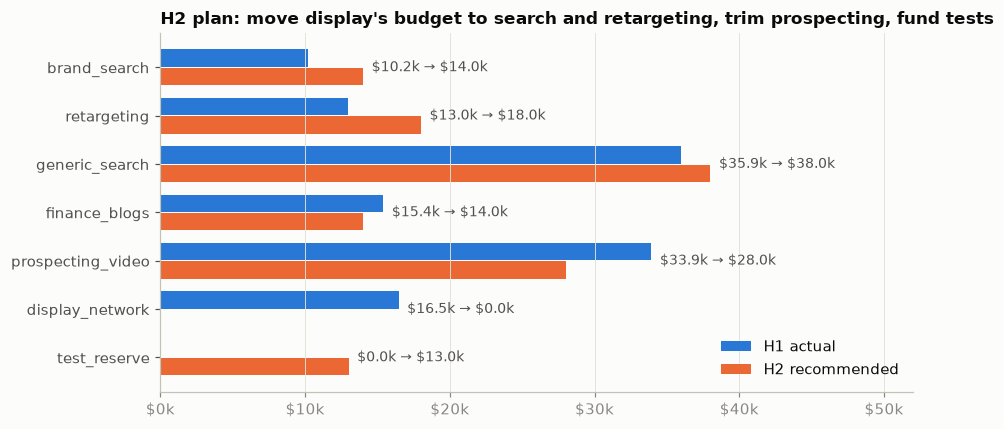

In [16]:
# Figure 4: H1 actual vs H2 recommended spend
b = budget.reset_index().rename(columns={"index": "campaign"})
y = np.arange(len(b)); h = 0.36
fig, ax = plt.subplots(figsize=(8.5, 4))
ax.barh(y - h / 2 - 0.01, b["h1_spend"], height=h, color=SERIES[0], label="H1 actual")
ax.barh(y + h / 2 + 0.01, b["h2_budget"], height=h, color=SERIES[1], label="H2 recommended")
for yi, v1, v2 in zip(y, b["h1_spend"], b["h2_budget"]):
    ax.text(max(v1, v2) + 600, yi, f"\${v1/1000:.1f}k → \${v2/1000:.1f}k", va="center", fontsize=9, color=INK2)
ax.set_yticks(y, b["campaign"]); ax.tick_params(axis="y", colors=INK2); ax.invert_yaxis()
ax.grid(axis="y", visible=False); ax.set_xlim(0, 52_000)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"\${v/1000:.0f}k"))
ax.legend(loc="lower right", frameon=False)
ax.set_title("H2 plan: move display's budget to search and retargeting, trim prospecting, fund tests")
fig.tight_layout(); fig.savefig(FIG / "fig4_budget_plan.png", dpi=150, bbox_inches="tight"); plt.show()

### Recommendation (flat budget of about $125k)

| Campaign | H1 | H2 | Why |
|---|---|---|---|
| brand_search | $10.2k | **$14.0k** | Lowest CAC ($22) and 1.9x ROAS. Growth is capped by how many people search for "Robinhood". |
| retargeting | $13.0k | **$18.0k** | $31 CAC and 1.3x ROAS. Grow with frequency caps. |
| generic_search | $35.9k | **$38.0k** | Best channel for reaching new demand at scale: 21.5% conversion, $83 CAC. Watch the May-June CPC creep. |
| finance_blogs | $15.4k | **$14.0k** | $95 CAC, similar to generic search. Renegotiate toward cost-per-subscriber terms. |
| prospecting_video | $33.9k | **$28.0k** | $159 CAC and 3.3% conversion. Trim it but keep it: it fills the retargeting pool. Move bidding to optimise for Gold starts, not signups. |
| display_network | $16.5k | **$0** | $2,057 CAC. Already stopped in May; keep it off. |
| Test reserve | - | **$13.0k** | Holdout tests for brand search and retargeting, plus prospecting creative tests. |

### Risks
1. **Diminishing returns.** The projection uses H1 *average* CAC. Spend was flat every day in H1, so there is no evidence of the *marginal* CAC at higher budgets. Brand search is the most capped, because its volume depends on brand queries. Scale in steps and re-check monthly.
2. **Incrementality and attribution.** Brand search and retargeting probably capture users who would have joined anyway, through organic search or a later visit. Last-touch credit may also undervalue prospecting video, which feeds the retargeting audience and brand searches. Cutting prospecting too hard could shrink retargeting and brand performance. That is why the cut is limited to 17% and paired with holdout tests.
3. **The 90-day window understates and distorts value.** Annual plans book $79.99 upfront while monthly plans book at most $29.97. Nothing after day 90 is visible. No campaign except brand search and retargeting breaks even within 90 days, so the case for generic search and finance blogs depends on Gold retention beyond 90 days. Validate with cohort LTV before scaling them further.
4. **Small samples.** Display has 8 paying subscribers and finance blogs about 25 a month, so their monthly CACs are noisy.
5. **Seasonality and market conditions.** Brokerage signups track market activity. H2 conditions may differ from H1.